# Git y GitHub: guía práctica para el proyecto

Al finalizar podrás guardar versiones, colaborar con pull requests y organizar una entrega con Gitflow.

Esta guía se lee en Jupyter o VS Code. Copia los bloques de comandos en una **terminal**, uno a uno; no son código Python. Sustituye los nombres y URL de ejemplo. Necesitas Git, una cuenta de GitHub y un editor.



## 1. Conceptos básicos
Git conserva el historial de un proyecto y permite comparar e integrar cambios. GitHub aloja repositorios Git y ofrece herramientas para coordinar tareas y revisiones. Git funciona localmente sin internet; GitHub es un servicio al que compartimos cambios.

| Concepto | Significado |
|---|---|
| Repositorio | Archivos del proyecto y su historial. |
| Commit | Registro de cambios con autor, mensaje e identificador. |
| Rama | Línea de trabajo con nombre para desarrollar cambios separados. |
| origin | Nombre convencional del repositorio remoto. |
| Pull request (PR) | Propuesta para revisar e integrar cambios entre ramas en GitHub. |
| Issue | Tarea, error o pregunta que sigue el equipo. |
| Tag | Referencia a un punto del historial, por ejemplo una entrega. |

El recorrido habitual es **editar → revisar → add → commit → push → PR → revisión → integración**. Un commit no está en GitHub hasta compartirlo con push.



## 2. Preparar el repositorio
Comprueba Git y configura tu identidad (puedes usar el correo noreply de GitHub):

```bash
git --version
git config --global user.name "Tu Nombre"
git config --global user.email "tu-correo"
```

Una persona crea en GitHub un repositorio con README y añade al resto como colaboradores. Usaremos `main` como rama estable: comprueba su nombre en GitHub. Cada integrante clona el mismo repositorio:

```bash
git clone https://github.com/USUARIO/REPOSITORIO.git
cd REPOSITORIO
git status
git remote -v
```

Autentícate con el gestor de credenciales o configura SSH. La contraseña de tu cuenta no sirve como contraseña de Git por HTTPS. No incluyas tokens en archivos.

**Comprueba:** status muestra tu rama y los cambios pendientes; remote muestra la URL del repositorio.



## 3. Preparar develop
Una sola persona crea la rama de integración:

```bash
git switch main
git pull --ff-only origin main
git switch -c develop
git push -u origin develop
```

Los demás, si aún no tienen develop local:

```bash
git fetch origin
git switch --track origin/develop
```

Si ya existe localmente, usa `git switch develop` y `git pull --ff-only origin develop`. Revisa status antes de cambiar de rama y guarda los cambios pendientes.



## 4. Primera funcionalidad y pull request
Cada persona elige una rama distinta. Ejemplo: documentar el objetivo del proyecto de NLP.

```bash
git switch develop
git pull --ff-only origin develop
git switch -c feature/objetivo-proyecto
```

Edita README.md: añade el objetivo, el tipo de texto que analizarán y una métrica de evaluación. Guarda el archivo y ejecuta:

```bash
git status
git diff
git add README.md
git diff --staged
git commit -m "docs: describe objetivo y evaluación"
git push -u origin feature/objetivo-proyecto
```

`add` selecciona cambios para el commit; `diff --staged` muestra lo seleccionado. El commit se guarda localmente y push lo comparte. Usa mensajes que expliquen qué cambió.

En GitHub:
1. Abre **Pull requests → New pull request**.
2. Elige **base: develop**, **compare: feature/objetivo-proyecto**.
3. Describe qué cambió, por qué y cómo lo comprobaste. Vincula la issue, si existe.
4. Un compañero revisa el cambio y deja comentarios o aprobación.
5. Atiende los comentarios con nuevos commits y push en la misma rama; el PR se actualiza.
6. Integra con **Create a merge commit** para conservar el historial de ramas de esta práctica. Comprueba que el repositorio permite esa opción.
7. Elimina la rama remota de la funcionalidad tras integrarla.

Actualiza tu copia:

```bash
git switch develop
git pull --ff-only origin develop
git branch -d feature/objetivo-proyecto
git log --oneline --graph --all --decorate
```

**Pregunta:** ¿por qué el PR iba hacia develop y no hacia main?



## 5. Gitflow: interpretar la imagen 

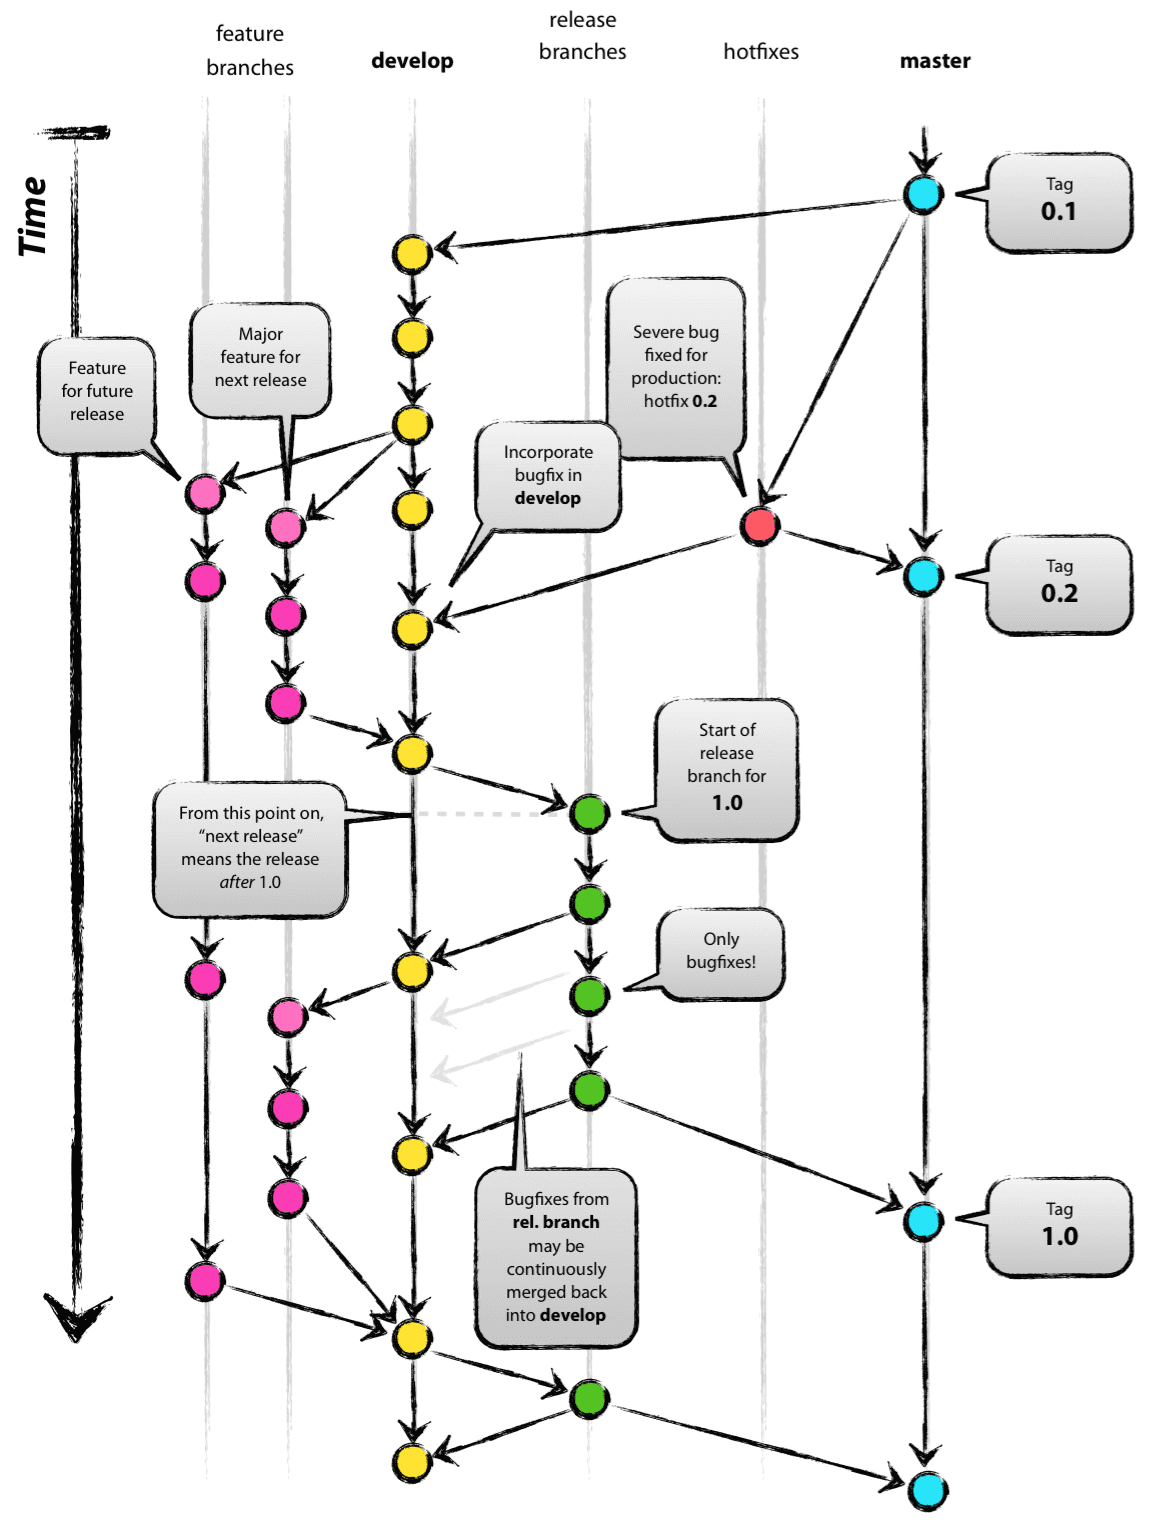

Imagen aportada por el usuario, conservada sin modificar. Modelo de Vincent Driessen; [fuente y atribución](https://nvie.com/files/Git-branching-model.pdf), licencia indicada en la fuente: Creative Commons BY-SA.

Lee la imagen **de arriba hacia abajo**: así avanza el tiempo. Los círculos representan commits. Las flechas muestran continuidad, creación de ramas e integración. Los colores son una ayuda visual; Git no asigna esos colores a las ramas.

| Imagen | Nuestro proyecto | Nace de | Se integra en | Uso |
|---|---|---|---|---|
| master, azul | main | Rama estable inicial | — | Entregas estables. |
| develop, amarillo | develop | main al iniciar | Mediante release | Integra la próxima entrega. |
| feature, rosa | feature/limpieza-texto | develop | develop | Una funcionalidad. |
| release, verde | release/1.0.0 | develop | main y develop | Estabilizar una versión. |
| hotfix, rojo | hotfix/1.0.1 | main | main y develop | Corregir una entrega urgente. |

`master` es el nombre histórico de la imagen; aquí usamos `main` con el mismo papel.

### Recorrido por el diagrama
1. Arriba a la derecha está la entrega 0.1. Desde esa línea estable se inicia develop.
2. Las ramas rosas parten de develop. Una funcionalidad vuelve antes; otra sigue trabajando para una versión futura. No todas deben entrar en la misma entrega.
3. El hotfix rojo parte de la versión estable, corrige un error y vuelve a master para publicar 0.2. También llega a develop para conservar la corrección en el trabajo futuro.
4. Al preparar 1.0, la rama verde sale de develop. Se congela el alcance: correcciones y ajustes de documentación o versión, sin añadir funcionalidades nuevas.
5. Las correcciones de la release regresan a develop. Al terminar, también se integra en master y se marca la versión 1.0.
6. Develop sigue avanzando para entregas futuras mientras la release se estabiliza.

**Regla clave:** una corrección publicada también debe llegar a develop. Si hay una release activa, revisa si necesita ese hotfix para no reintroducir el error. Las ramas temporales se eliminan tras completar sus integraciones.

Gitflow es una convención de trabajo; no hace falta instalar la extensión git-flow. **GitHub Flow** es una estrategia distinta y más sencilla: ramas de trabajo y PR hacia la rama principal. En esta práctica usamos Gitflow para aprender a organizar entregas versionadas.



## 6. Preparar y publicar una entrega
Una persona coordina la release. Ejecuta cada etapa cuando termine la anterior.

```bash
git switch develop
git pull --ff-only origin develop
git switch -c release/1.0.0
git push -u origin release/1.0.0
```

Comprueben que el notebook corre desde cero, que las rutas y dependencias están documentadas y que los resultados son reproducibles. Guarden las correcciones con add, commit y push en la release.

1. Abre PR **release/1.0.0 → main**, revisa e integra con merge commit.
2. Actualiza main y marca la entrega:

```bash
git switch main
git pull --ff-only origin main
git tag -a v1.0.0 -m "Primera entrega del proyecto"
git push origin v1.0.0
```

3. Abre PR **release/1.0.0 → develop** para conservar las correcciones. Integra y solo entonces elimina la rama release.
4. Opcional: crea en GitHub una Release desde v1.0.0 con notas de cambios y limitaciones.

Una release branch permite preparar cambios; un tag identifica un commit; una GitHub Release añade notas y archivos asociados a un tag.

### Ampliación: hotfix
Tras publicar, detectan una instrucción errónea en el README que impide ejecutar el proyecto:

```bash
git switch main
git pull --ff-only origin main
git switch -c hotfix/1.0.1
```

Corrige README.md y guarda:

```bash
git add README.md
git commit -m "fix: corrige instrucción de ejecución"
git push -u origin hotfix/1.0.1
```

Integra mediante PR **hotfix/1.0.1 → main**. Actualiza main y crea/publica el tag v1.0.1 siguiendo el ejemplo anterior. Integra también **hotfix/1.0.1 → develop**. Si hay una release activa, comprueba si requiere la corrección. Elimina el hotfix tras completar las integraciones.



## 7. Conflictos y dudas frecuentes
Si dos personas cambian la misma línea, Git puede necesitar una decisión humana. Para integrar develop en una feature, comienza con los cambios locales guardados:

```bash
git switch feature/objetivo-proyecto
git fetch origin
git merge origin/develop
```

Si aparece un conflicto, usa status para identificar archivos. Abre el archivo, busca las marcas `<<<<<<<`, `=======` y `>>>>>>>`, acuerda el contenido final y elimina esas marcas. Verifica el resultado y guarda (usa el archivo realmente afectado):

```bash
git add README.md
git commit -m "merge: resuelve conflicto del README"
git push
```

Para cancelar el merge en curso: `git merge --abort`. En notebooks evita resolver el JSON a ciegas: coordina quién edita cada archivo o usa una herramienta que entienda ipynb.

| Problema | Qué hacer |
|---|---|
| nothing to commit | Comprueba que guardaste el archivo y estás en la carpeta correcta. |
| Push rechazado | Haz fetch y revisa el historial con tu equipo antes de integrar; no fuerces el push. |
| pull --ff-only falla | Las historias divergieron; revisa e integra conscientemente con el equipo. |
| La rama ya existe | Usa switch sin -c; -c crea una rama nueva. |
| No permite cambiar de rama | Revisa y guarda los cambios pendientes. |
| PR con destino incorrecto | Cambia la base antes de fusionarlo. |



## 8. Aplicación al proyecto de NLP
Acuerden una issue por tarea con responsable y criterio de aceptación. Ejemplos: carga de datos, limpieza del texto, modelo base y evaluación. Cada tarea usa su feature y un PR hacia develop, revisado por otra persona. Main contiene entregas verificadas. Si la cuenta lo permite, configuren reglas que exijan PR y revisión en main y develop.

No suban credenciales, datos personales ni datasets sin autorización. Documenten el acceso a los datos y usen muestras permitidas. Eviten versionar entornos virtuales, cachés y modelos grandes. Borren salidas innecesarias de notebooks y distribuyan los archivos para reducir conflictos.

Ejemplo de .gitignore, que deben adaptar:

```gitignore
.venv/
__pycache__/
.ipynb_checkpoints/
.env
data/raw/
models/
```

.gitignore no deja de rastrear archivos ya versionados. Si publicaron una credencial, revóquenla y coordinen su retirada del historial; borrarla de la última versión no basta.

Plantilla de PR:

```text
Qué cambia:
Por qué:
Cómo se verificó (pasos y resultado):
Issue relacionada:
Limitaciones pendientes:
```



## 9. Reto y comprobación del aprendizaje
En equipo, creen dos issues pequeñas, implementen cada una en una feature distinta, intercambien revisiones e integren los PR. Preparen una release y publiquen el tag v1.0.0. Si falta tiempo, practiquen solo con documentación y dejen el hotfix como ampliación.

**Evidencia:** enlace al repositorio, dos PR revisados, tag de entrega y un párrafo sobre el reparto del trabajo.

Responde antes de consultar la solución:
1. ¿En qué se diferencian commit y push?
2. ¿De dónde nace una feature y a dónde vuelve?
3. ¿Por qué un hotfix no se queda solo en main?
4. ¿Por qué no añadir funcionalidades durante la estabilización de una release?

**Respuestas orientativas:** commit guarda cambios localmente y push los comparte; la feature nace de develop y vuelve allí; el hotfix debe conservarse en versiones futuras; la release busca cerrar alcance y comprobar estabilidad.

## Referencias
- [Libro oficial de Git en español](https://git-scm.com/book/es/v2): conceptos y comandos.
- [GitHub: pull requests](https://docs.github.com/en/pull-requests/get-started): propuesta, discusión y revisión de cambios.
- [GitHub: práctica de un PR](https://docs.github.com/en/pull-requests/get-started/pull-request-quickstart): pasos de colaboración.
- [Modelo original de Vincent Driessen y reflexión posterior](https://nvie.com/posts/a-successful-git-branching-model/): contexto de Gitflow.